<a href="https://colab.research.google.com/github/VishnuCodes96/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP4_AirQuality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Importing the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as pe

## Loading the dataset using Pandas

In [2]:
url = "https://raw.githubusercontent.com/urbanemissions-info/AQI_bulletins/main/data/Processed/AllIndiaBulletins_Master.csv"
df = pd.read_csv(url, low_memory=False)

### Displaying First and Last 5 rows

In [3]:
df.head()

,date,City,No. Stations,Air Quality,Index Value,Prominent Pollutant
0,2015-05-01,Varanasi,NaN,Moderate,157,PM10
1,2015-05-01,Kanpur,NaN,Moderate,175,PM10
2,2015-05-01,Faridabad,NaN,Moderate,173,PM10
3,2015-05-01,Ahmedabad,NaN,Moderate,168,PM2.5
4,2015-05-01,Hyderabad,NaN,Moderate,189,PM2.5


In [4]:
df.tail()

,date,City,No. Stations,Air Quality,Index Value,Prominent Pollutant
299969,2023-12-31,Moradabad,6,Satisfactory,97,"PM10, PM2.5"
299970,2023-12-31,Milupara,1,Moderate,134,PM2.5
299971,2023-12-31,Meerut,3,Moderate,173,PM2.5
299972,2023-12-31,Pratapgarh,1,Poor,248,PM2.5
299973,2023-12-31,Sangli,1,Moderate,111,PM2.5


### Infromation about the whole dataset

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299974 entries, 0 to 299973
Data columns (total 6 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   date                 299974 non-null  object
 1   City                 299974 non-null  object
 2   No. Stations         299834 non-null  object
 3   Air Quality          299974 non-null  object
 4   Index Value          299974 non-null  int64 
 5   Prominent Pollutant  299973 non-null  object
dtypes: int64(1), object(5)
memory usage: 13.7+ MB


### Missing values in No. Stations is `140` and Prominent Pollutant column is `1`

In [6]:
print("No. of Rows & Columns: ",df.shape)
print("Name of the Columns: ",df.columns)

No. of Rows & Columns:  (299974, 6)
Name of the Columns:  Index(['date', 'City', 'No. Stations', 'Air Quality', 'Index Value',
       'Prominent Pollutant'],
      dtype='object')


### Counting rows that repeat the same date and City

In [7]:
df.duplicated(subset=["date", "City"]).sum()

np.int64(34)

In [8]:
df.duplicated(subset=["date", "City"]).value_counts()

,count
False,299940
True,34


### How many different cities are there? What are the first and last dates?

In [9]:
print(f'Number of Cities in the dataset: {df['City'].nunique()}')

Number of Cities in the dataset: 277


In [10]:
print(f'First date recorded in the dataset: {df['date'].min()}')

First date recorded in the dataset: 2015-05-01


In [11]:
print(f'Latest date recorded in the dataset: {df['date'].max()}')

Latest date recorded in the dataset: 2023-12-31


### Show the count of each value in Air Quality. What do you notice about the spellings?

In [12]:
df['Air Quality'].value_counts()

,count
Air Quality,
Satisfactory,105251
Moderate,96139
Good,47440
Poor,34641
Very Poor,13969
Severe,2516
Very poor,18


#### Every category is in Title Case, except 'Very Poor' cateogry is repeated twice once in Title Case and once in normal case

## Cleaning the Dataset

### Converting date into a proper datetime column.

In [13]:
df['date'] = pd.to_datetime(df['date'])
print(f'Date column datatype changed to {df['date'].dtype}')

Date column datatype changed to datetime64[ns]


In [14]:
df.shape

(299974, 6)

### Fixing the Air Quality spellings so each category appears once.

In [15]:
df['Air Quality'] = df['Air Quality'].str.title()

In [16]:
df['Air Quality'].value_counts()

,count
Air Quality,
Satisfactory,105251
Moderate,96139
Good,47440
Poor,34641
Very Poor,13987
Severe,2516


In [17]:
df.shape

(299974, 6)

### Removing repeated city-days, keeping the first one

In [18]:
df = df.drop_duplicates(subset=['date','City'], keep='first')

#### No. of duplicate rows = 34, No. of rows in unaltered dataset = 299974, No. of rows after removing duplicates based only on the combination of date and city = 299974 - 34 => 299940

In [19]:
df.shape

(299940, 6)

### Dropping the `No. Stations` column.

In [20]:
df = df.drop(columns=['No. Stations'])

In [21]:
df.shape

(299940, 5)

#### Reason for dropping `No. Stations` column: This project focuses on analyzing city-level AQI trends, air quality categories, and prominent pollutants, and the number of monitoring stations is not essential to the primary analysis. Although dropping it is reasonable for the current project, the number of monitoring stations could influence how representative a city's AQI measurement is. So it may be useful in a more detailed study.

### Creating two new columns: year and month

In [22]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
# Pandas provides the '.dt' accessor to extract date-related information.

In [23]:
df[['date','year','month']].head()

,date,year,month
0,2015-05-01,2015,5
1,2015-05-01,2015,5
2,2015-05-01,2015,5
3,2015-05-01,2015,5
4,2015-05-01,2015,5


In [24]:
df.shape

(299940, 7)

### replacing "OZONE" with "O3" in Prominent Pollutant.

In [25]:
df['Prominent Pollutant'] = df['Prominent Pollutant'].replace('OZONE','O3')

In [26]:
df[df['Prominent Pollutant'] == 'O3'].head(2)

,date,City,Air Quality,Index Value,Prominent Pollutant,year,month
6,2015-05-01,Delhi,Poor,221,O3,2015,5
28,2015-05-03,Agra,Satisfactory,84,O3,2015,5


## AQI with statistics

In [27]:
print(f'Air Quality Index mean for India is: {round(df['Index Value'].mean(),2)}')
print(f'Air Quality Index median for India is: {df['Index Value'].median()}')
print(f'Air Quality Index standard deviation for India is: {round(df['Index Value'].std(),2)}')
print(f'Air Quality Index maximum value for India is: {df['Index Value'].max()}')
print(f'Air Quality Index minimum value for India is: {df['Index Value'].min()}')

Air Quality Index mean for India is: 124.69
Air Quality Index median for India is: 99.0
Air Quality Index standard deviation for India is: 85.09
Air Quality Index maximum value for India is: 500
Air Quality Index minimum value for India is: 3


### Only for DELHI

In [28]:
delhi_df = df[df['City'] == 'Delhi']
delhi_df.shape

(3143, 7)

In [29]:
print(f'Air Quality Index mean for Delhi is: {round(delhi_df['Index Value'].mean(),2)}')
print(f'Air Quality Index median for Delhi is: {delhi_df['Index Value'].median()}')
print(f'Air Quality Index standard deviation for Delhi is: {round(delhi_df['Index Value'].std(),2)}')
print(f'Air Quality Index maximum value for Delhi is: {delhi_df['Index Value'].max()}')
print(f'Air Quality Index minimum value for Delhi is: {delhi_df['Index Value'].min()}')

Air Quality Index mean for Delhi is: 217.14
Air Quality Index median for Delhi is: 209.0
Air Quality Index standard deviation for Delhi is: 104.01
Air Quality Index maximum value for Delhi is: 497
Air Quality Index minimum value for Delhi is: 41


### Note:
* The descriptive statistical analysis indicates that Delhi experienced considerably poorer air quality compared to the overall dataset average. Delhi recorded a mean AQI of 217.14 and a median of 209, whereas the corresponding national values were 124.69 and 99.
* Delhi also exhibited greater AQI variability, with a standard deviation of 104.01 compared to India's 85.09. Both datasets recorded extremely high maximum AQI values, indicating episodes of severe air pollution.

### Calculating Q1, Q3 and the IQR (Q3 minus Q1) of AQI

In [30]:
Q1_india = df['Index Value'].quantile(0.25)
Q3_india = df['Index Value'].quantile(0.75)
IQR_india = Q3_india - Q1_india
print("India Q1:", Q1_india)
print("India Q3:", Q3_india)
print("India IQR:", IQR_india)

India Q1: 62.0
India Q3: 162.0
India IQR: 100.0


### Q1, Q3 and IQR for Delhi

In [31]:
Q1_delhi = delhi_df['Index Value'].quantile(0.25)
Q3_delhi = delhi_df['Index Value'].quantile(0.75)
IQR_delhi = Q3_delhi - Q1_delhi
print("Delhi Q1:", Q1_delhi)
print("Delhi Q3:", Q3_delhi)
print("Delhi IQR:", IQR_delhi)

Delhi Q1: 127.0
Delhi Q3: 296.0
Delhi IQR: 169.0


### Calculating Skewness

In [32]:
india_skew = df['Index Value'].skew()
print("India AQI Skewness:", round(india_skew,2))

India AQI Skewness: 1.34


### Delhi's Skewness

In [33]:
delhi_skew = delhi_df['Index Value'].skew()
print("Delhi AQI Skewness:", round(delhi_skew,2))

Delhi AQI Skewness: 0.3


### Note:
* India's skewness of 1.34 indicates a strongly right-skewed distribution.
* Delhi's 0.3 suggests a relatively symmetric distribution with a slight right skew.

### counting how many Delhi days are outliers

In [34]:
upper_bound = Q3_delhi + (1.5 * IQR_delhi)
print("Upper Bound:", upper_bound)

Upper Bound: 549.5


In [35]:
delhi_outliers = delhi_df[delhi_df['Index Value'] > upper_bound]
print("Number of Delhi outlier days:", len(delhi_outliers))

Number of Delhi outlier days: 0


### Drawing a histogram of Delhi's AQI

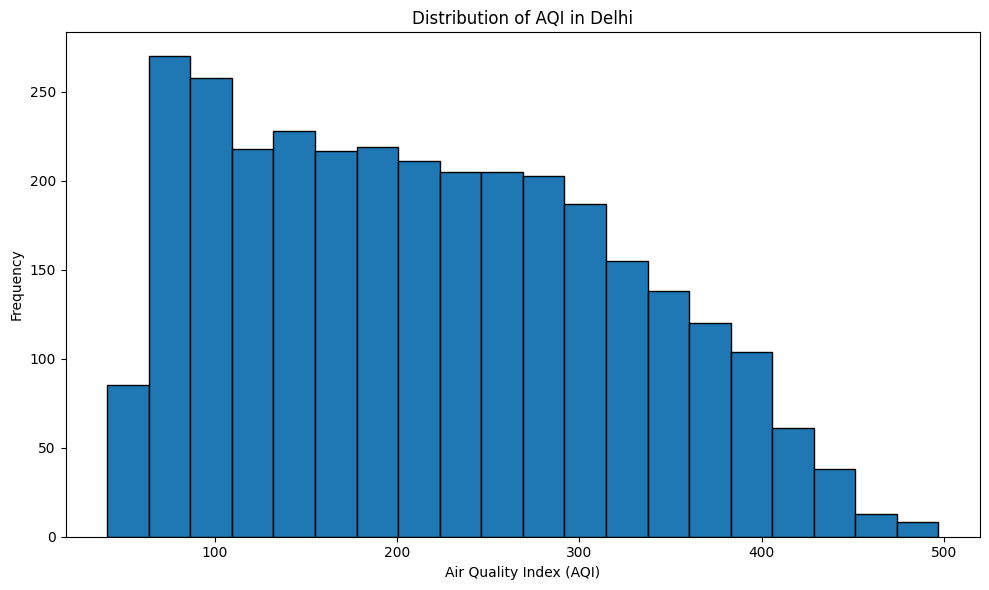

In [36]:
plt.figure(figsize=(10, 6))

plt.hist(delhi_df['Index Value'], bins=20, edgecolor='black')

plt.title('Distribution of AQI in Delhi')
plt.xlabel('Air Quality Index (AQI)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### Note:
* The histogram of Delhi's AQI distribution indicates a mildly right-skewed distribution. Most observations are concentrated between approximately 60 and 300 AQI, while higher AQI values occur less frequently. This is consistent with the calculated skewness of 0.3.

### Drawing box plot comparing five cities: Delhi, Mumbai, Kolkata, Chennai and Bengaluru.

In [37]:
cities = ['Delhi', 'Mumbai', 'Kolkata', 'Chennai', 'Bengaluru']
city_df = df[df['City'].isin(cities)]
city_df.head()

,date,City,Air Quality,Index Value,Prominent Pollutant,year,month
5,2015-05-01,Chennai,Satisfactory,87,CO,2015,5
6,2015-05-01,Delhi,Poor,221,O3,2015,5
13,2015-05-02,Delhi,Poor,238,"O3, PM2.5",2015,5
14,2015-05-02,Chennai,Moderate,120,PM2.5,2015,5
15,2015-05-02,Bengaluru,Moderate,132,"CO, PM2.5",2015,5


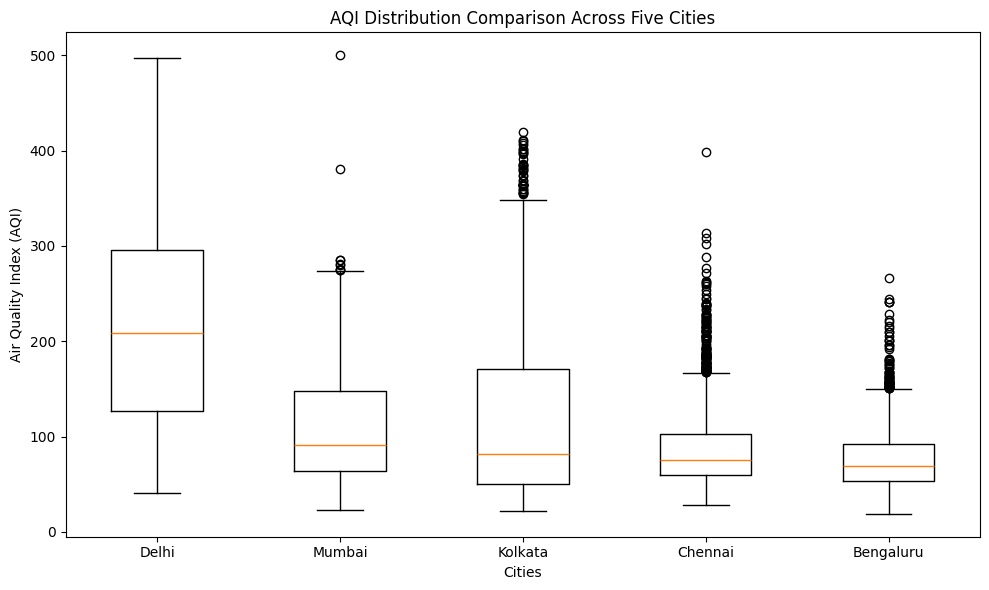

In [38]:
plt.figure(figsize=(10, 6))

data = [ city_df[city_df['City'] == city]['Index Value'] for city in cities]

plt.boxplot(data, tick_labels=cities)

plt.title('AQI Distribution Comparison Across Five Cities')
plt.xlabel('Cities')
plt.ylabel('Air Quality Index (AQI)')
plt.tight_layout()
plt.show()

### Note:
I used List Comprehension, to create the data.

It performs the following operations:
1. Takes Delhi from the cities list.
2. Filters the DataFrame to get Delhi's AQI values.
3. Repeats the same operation for Mumbai, Kolkata, Chennai and Bengaluru.
4. Stores all five collections of AQI values in a Python list.

### City-wise observations
1. Delhi
- Has the highest median AQI (approximately 209).
- Has a very wide IQR, indicating substantial variability in its middle 50% of observations.
- Its AQI distribution is considerably higher than the other four cities.
- No visible outliers under the box plot's default 1.5 × IQR rule.
2. Mumbai
- Median AQI is approximately 90.
- Most observations are concentrated between approximately 65 and 150.
- Has a few extreme high-value outliers, including observations around 500.
- Its typical AQI is considerably lower than Delhi's.
3. Kolkata
- Median AQI is approximately 82.
- Has a relatively wide IQR.
- Shows numerous high-AQI outliers, extending beyond 400.
- Its distribution indicates considerable variation in recorded AQI.
4. Chennai
- Median AQI is approximately 75.
- Has a relatively narrow IQR.
- Contains numerous high-value outliers.
- Most observations are concentrated within a relatively low AQI range.
5. Bengaluru
- Has the lowest median AQI (approximately 68).
- Has a relatively narrow IQR.
- Contains several high-value outliers.
- Its typical AQI is lower than the other four cities.

### Conclusion:
The box plot comparison reveals significant differences in AQI distributions across the five cities. Delhi has the highest median AQI and the widest interquartile range, indicating higher typical pollution levels and greater variability. Bengaluru has the lowest median AQI, followed by Chennai. Kolkata, Chennai and Bengaluru exhibit several high-AQI outliers, suggesting occasional pollution spikes despite their comparatively lower median values. Overall, Delhi demonstrates the poorest typical air quality among the five cities.

## Which cities have the worst air?

### Counting the days per city and keeping the cities with 2,000 or more.

In [39]:
city_days = df.groupby('City')['date'].count()
city_days.head()

,date
City,
Agartala,1084
Agra,2922
Ahmedabad,2538
Aizawl,1129
Ajmer,2121


In [40]:
eligible_cities = city_days[city_days >= 2000]
print("Number of eligible cities:", len(eligible_cities))

Number of eligible cities: 54


### finding the average AQI

In [41]:
eligible_df = df[df['City'].isin(eligible_cities.index)] #creating eligible cities dataframe

In [42]:
avg_aqi = eligible_df.groupby('City')['Index Value'].mean() #calculating the average separately for each city, not the average across all cities.

In [43]:
worst_10 = avg_aqi.nlargest(10)
print("Top 10 Cities with Highest Average AQI:")
print(worst_10)

Top 10 Cities with Highest Average AQI:
City
Ghaziabad        221.638131
Delhi            217.135857
Bhiwadi          215.921958
Greater Noida    210.982793
Noida            206.009975
Faridabad        205.646133
Gurugram         198.646970
Muzaffarpur      193.523030
Patna            190.402317
Lucknow          181.163613
Name: Index Value, dtype: float64


In [44]:
best_5 = avg_aqi.nsmallest(5)
print("Top 5 Cities with Lowest Average AQI:")
print(best_5)

Top 5 Cities with Lowest Average AQI:
City
Thiruvananthapuram    59.171664
Tirupati              70.750400
Bengaluru             75.419872
Amaravati             77.452217
Rajamahendravaram     84.371325
Name: Index Value, dtype: float64


### Observation:
The city-wise average AQI analysis reveals that Ghaziabad has the highest average AQI of 221.64, followed by Delhi and Bhiwadi. A significant concentration of highly polluted cities is observed in the Delhi-NCR region. On the other hand, Thiruvananthapuram has the lowest average AQI of 59.17, followed by Tirupati and Bengaluru. The results indicate substantial geographical variation in air quality across Indian cities, with southern cities dominating the lowest-average-AQI rankings.

### Visualizing The 10 worst cities in terms of AQI

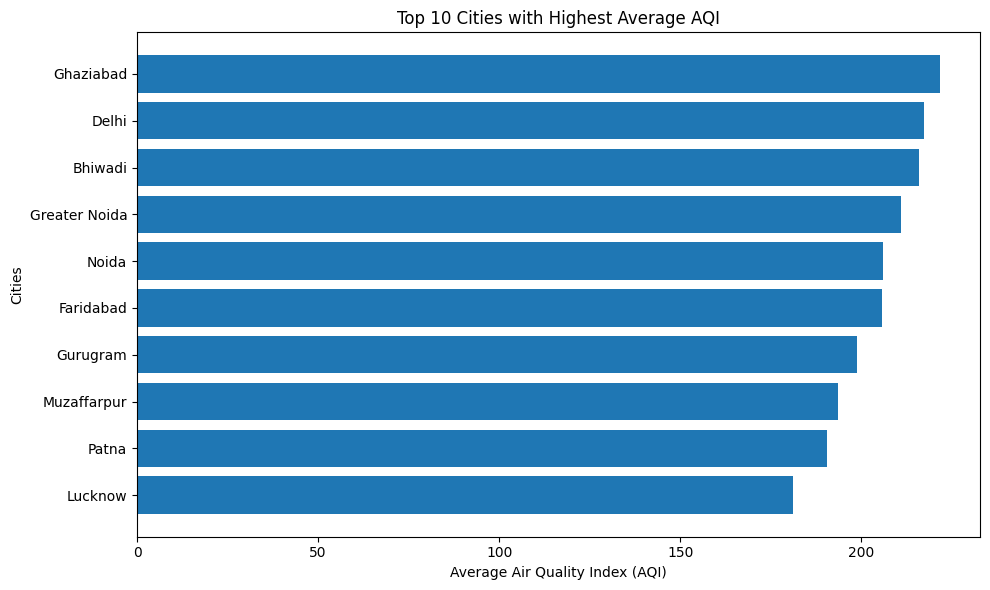

In [45]:
plt.figure(figsize=(10, 6))

plt.barh(worst_10.index, worst_10.values)

plt.title('Top 10 Cities with Highest Average AQI')
plt.xlabel('Average Air Quality Index (AQI)')
plt.ylabel('Cities')

plt.gca().invert_yaxis() # Places the highest AQI city at the top
plt.tight_layout()
plt.show()

### Calculating the share of days rated Poor or worse (AQI above 200)

In [46]:
poor_days = eligible_df[eligible_df['Index Value'] > 200]
poor_days.head()

,date,City,Air Quality,Index Value,Prominent Pollutant,year,month
6,2015-05-01,Delhi,Poor,221,O3,2015,5
11,2015-05-02,Faridabad,Poor,299,PM10,2015,5
13,2015-05-02,Delhi,Poor,238,"O3, PM2.5",2015,5
16,2015-05-02,Ahmedabad,Poor,225,PM2.5,2015,5
20,2015-05-03,Varanasi,Poor,211,PM10,2015,5


In [47]:
poor_days_count = poor_days.groupby('City')['Index Value'].count()
total_days = eligible_df.groupby('City')['Index Value'].count()

poor_day_share = (poor_days_count / total_days) * 100
top_10_poor_share = poor_day_share.nlargest(10)

print("Top 10 Cities by Share of Poor AQI Days:")
print(top_10_poor_share)

Top 10 Cities by Share of Poor AQI Days:
City
Bhiwadi          54.386815
Ghaziabad        52.646816
Delhi            52.433980
Greater Noida    49.065880
Faridabad        46.646133
Gurugram         46.255175
Noida            46.217789
Muzaffarpur      45.108489
Patna            42.972973
Lucknow          38.547120
Name: Index Value, dtype: float64


### Are the two top-10 lists the same? What do most of the worst cities have in common?
* Yes, both top-10 lists contain exactly the same 10 cities, although their rankings differ slightly between the two measures.
* Most of these cities are concentrated in the Delhi-NCR region and the Indo-Gangetic Plain, indicating a regional concentration of poor air quality.